In [1]:
import json
import math
import tkinter as tk
from tkinter import messagebox, ttk

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import FloatSlider, IntSlider, interact
from matplotlib.colors import ListedColormap
from mpl_toolkits.mplot3d import Axes3D

import manim as mn
from manim import *

In [2]:
config.media_width = "75%"
config.verbosity = "WARNING"
config.background_color = BLUE
Text.set_default(color=BLACK, stroke_color=BLACK)
MathTex.set_default(color=BLACK, stroke_color=BLACK)

In [3]:
# plt.style.available

# ggplot_style = plt.style.library['seaborn-v0_8-paper']

# # View what's in it
# print(ggplot_style)

In [4]:
plt.style.use('style.mplstyle')
#plt.style.use('seaborn-v0_8-paper')

In [5]:
power = 80
atk = 150
base_health = 150
base_defense = 80
level = 50

defense_evs = 0
health_evs = 0
total_evs = 0

In [6]:
damage = (( (2*level/5 + 2) * power * (atk / base_defense) ) / 50) + 2

damage

68.0

In [7]:
%%manim -qm DamageFormula

class DamageFormula(Scene):
    def construct(self):
        formula = MathTex(r"damage = (\frac{(\frac{2 * Level}{5} + 2) * Power * \frac{Attack}{Defense}}{50} + 2) * Extras")
        self.play(Write(formula), run_time=3)
        self.wait()

Manim Community v0.20.1

In [8]:
%%manim -qm TransformEquation

class TransformEquation(Scene):
    def construct(self):
        eq1 = MathTex(r"damage = (\frac{(\frac{2 * Lvl}{5} + 2) * Power * \frac{Atk}{Def}}{50} + 2) * Extras")
        eq2 = MathTex(r"damage = (\frac{(\frac{2 * 50}{5} + 2) * Power * \frac{Atk}{Def}}{50} + 2) * Extras")
        eq3 = MathTex(r"damage = (\frac{22 * Power * \frac{Atk}{Def}}{50} + 2) * Extras")
        eq4 = MathTex(r"damage = (\frac{22}{50} * Power * \frac{Atk}{Def} + 2) * Extras")
        eq5 = MathTex(r"damage = (0.44 * Power * \frac{Atk}{Def} + 2) * Extras")
        simpEQ = MathTex(r"damage \propto \frac{Power}{2} * \frac{Atk}{Def}")
        self.add(eq1)
        self.wait()
        self.play(TransformMatchingTex(eq1, eq2))
        self.wait()
        self.play(TransformMatchingTex(eq2, eq3))
        self.wait()
        self.play(TransformMatchingTex(eq3, eq4))
        self.wait()
        self.play(TransformMatchingTex(eq4, eq5))
        self.wait(2)
        self.play(TransformMatchingTex(eq5, simpEQ))
        self.wait()

Manim Community v0.20.1

In [9]:
damage_percent = ((( (2*level/5 + 2) * power * (atk / base_defense) ) / 50) + 2 ) / base_health * 100

damage_percent

45.33333333333333

In [10]:
damage_percent = ((( (2*level/5 + 2) * power * (atk / (base_defense + defense_evs)) ) / 50) + 2 ) / (base_health + health_evs) * 100


In [11]:

# Constants
power = 80
atk = 150
base_health = 150
base_defense = 80
level = 50
total_evs = 510

# Define the damage_percent function
def damage_percent(defense_evs, health_evs):
    if defense_evs + health_evs > total_evs:  # Constraint check
        return 0  # Invalid solution
    return ((( (2*level/5 + 2) * power * (atk / (base_defense + defense_evs)) ) / 50) + 2 ) / (base_health + health_evs) * 100

# Grid search over all possible EV combinations
defense_range = np.arange(0, 253)  # EVs from 0 to 252
health_range = np.arange(0, 253)
max_damage_percent = 0
optimal_defense_evs = 0
optimal_health_evs = 0

for defense_evs in defense_range:
    for health_evs in health_range:
        if defense_evs + health_evs <= total_evs:  # Check total EV constraint
            current_damage_percent = damage_percent(defense_evs, health_evs)
            if current_damage_percent > max_damage_percent:
                max_damage_percent = current_damage_percent
                optimal_defense_evs = defense_evs
                optimal_health_evs = health_evs

print(f"Optimal Defense EVs: {optimal_defense_evs}")
print(f"Optimal Health EVs: {optimal_health_evs}")
print(f"Maximum Damage Percent: {max_damage_percent}")

Optimal Defense EVs: 0
Optimal Health EVs: 0
Maximum Damage Percent: 45.33333333333333


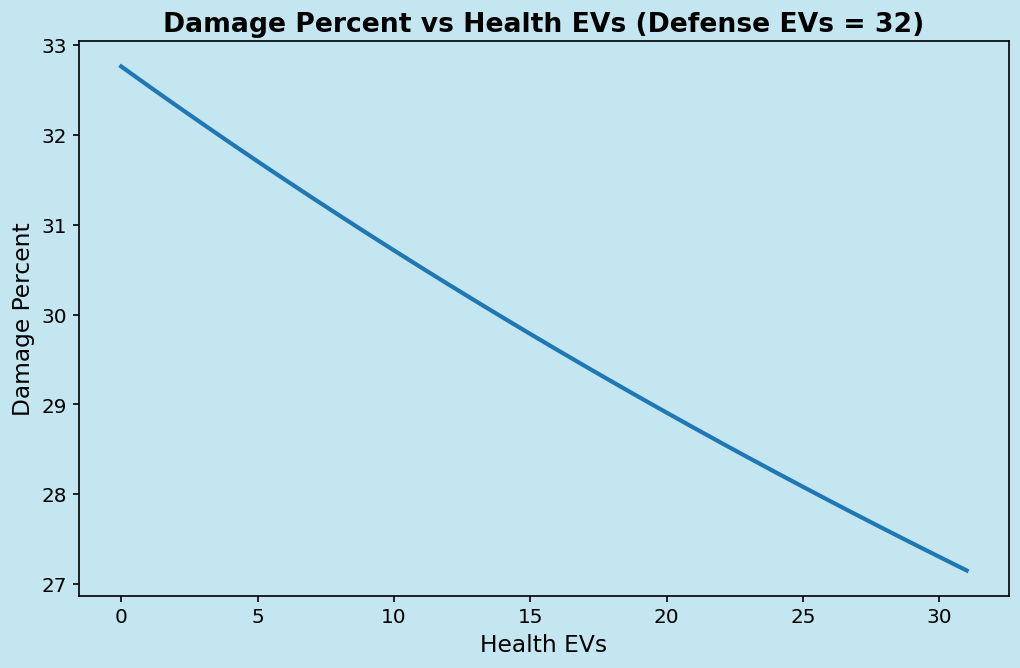

In [12]:

# Define the damage_percent function
def damage_percent(defense_evs, health_evs):
    if defense_evs + health_evs > total_evs:  # Constraint check
        return 0  # Invalid solution
    return ((( (2*level/5 + 2) * power * (atk / (base_defense + defense_evs)) ) / 50) + 2 ) / (base_health + health_evs) * 100

# Fix defense_evs and vary health_evs
defense_evs = 32  # Example fixed value
health_evs_range = np.arange(0, 32)
damage_percent_values = [damage_percent(defense_evs, health_evs) for health_evs in health_evs_range]

# Plot the curve
plt.plot(health_evs_range, damage_percent_values)
plt.xlabel('Health EVs')
plt.ylabel('Damage Percent')
plt.title(f'Damage Percent vs Health EVs (Defense EVs = {defense_evs})')
plt.show()

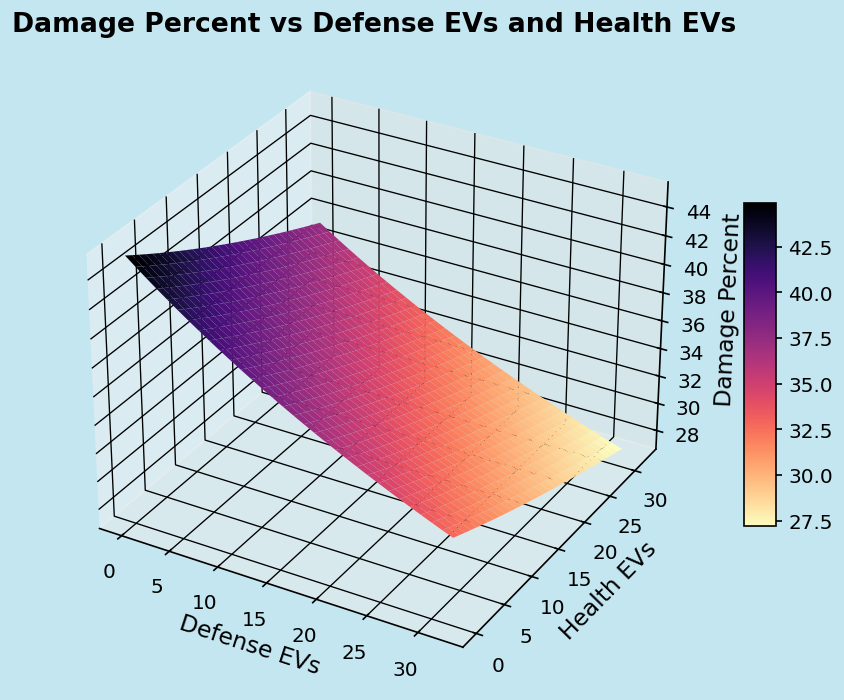

In [13]:


# Constants
power = 80
atk = 150
base_health = 150
base_defense = 80
level = 50
total_evs = 66


# Define the damage_percent function
def damage_percent(defense_evs, health_evs):
    if defense_evs + health_evs > total_evs:  # Constraint check
        return 0  # Invalid solution
    return ((( (2*level/5 + 2) * power * (atk / (base_defense + defense_evs)) ) / 50) + 2 ) / (base_health + health_evs) * 100

# Create a grid of defense_evs and health_evs
defense_evs_range = np.linspace(0, 32, 32)
health_evs_range = np.linspace(0, 32, 32)
defense_evs_grid, health_evs_grid = np.meshgrid(defense_evs_range, health_evs_range)

# Calculate damage_percent for each combination of defense_evs and health_evs
damage_percent_grid = np.zeros_like(defense_evs_grid)
for i in range(defense_evs_grid.shape[0]):
    for j in range(defense_evs_grid.shape[1]):
        defense_evs = defense_evs_grid[i, j]
        health_evs = health_evs_grid[i, j]
        if defense_evs + health_evs <= total_evs:  # Check total EV constraint
            damage_percent_grid[i, j] = damage_percent(defense_evs, health_evs)

# Plot the 3D surface
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(defense_evs_grid, health_evs_grid, damage_percent_grid, cmap='magma_r')

# Add labels and title
ax.set_xlabel('Defense EVs')
ax.set_ylabel('Health EVs')
ax.set_zlabel('Damage Percent')
ax.set_title('Damage Percent vs Defense EVs and Health EVs')

# Add a color bar
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10)

plt.show()

In [14]:
# Find the minimum damage_percent and its coordinates
min_damage_percent = np.min(damage_percent_grid)
min_index = np.unravel_index(np.argmin(damage_percent_grid), damage_percent_grid.shape)
optimal_defense_evs = defense_evs_grid[min_index]
optimal_health_evs = health_evs_grid[min_index]

print(f"Minimum Damage Percent: {min_damage_percent}")
print(f"Optimal Defense EVs: {optimal_defense_evs}")
print(f"Optimal Health EVs: {optimal_health_evs}")

Minimum Damage Percent: 27.001569858712713
Optimal Defense EVs: 32.0
Optimal Health EVs: 32.0


In [15]:


# Constants
power = 80
atk = 150
base_health = 150
base_defense = 80
level = 50
total_evs = 50

#create a set of hp and def evs that add up to total_evs maxing at 32 for each. Example [32, 18], [31, 19], [30, 20], etc.]


# Generate all valid combinations of hp_evs and def_evs
ev_combinations = [
    (hp, total_evs - hp)
    for hp in range(0, min(32, total_evs) + 1)
    if total_evs - hp <= 32
]

# Print the combinations
for hp, defense in ev_combinations:
    print(f"HP EVs: {hp}, Defense EVs: {defense}")

HP EVs: 18, Defense EVs: 32
HP EVs: 19, Defense EVs: 31
HP EVs: 20, Defense EVs: 30
HP EVs: 21, Defense EVs: 29
HP EVs: 22, Defense EVs: 28
HP EVs: 23, Defense EVs: 27
HP EVs: 24, Defense EVs: 26
HP EVs: 25, Defense EVs: 25
HP EVs: 26, Defense EVs: 24
HP EVs: 27, Defense EVs: 23
HP EVs: 28, Defense EVs: 22
HP EVs: 29, Defense EVs: 21
HP EVs: 30, Defense EVs: 20
HP EVs: 31, Defense EVs: 19
HP EVs: 32, Defense EVs: 18


Optimal HP EVs: 10
Optimal Defense EVs: 0
Maximum Damage Percent: 84.85490196078432


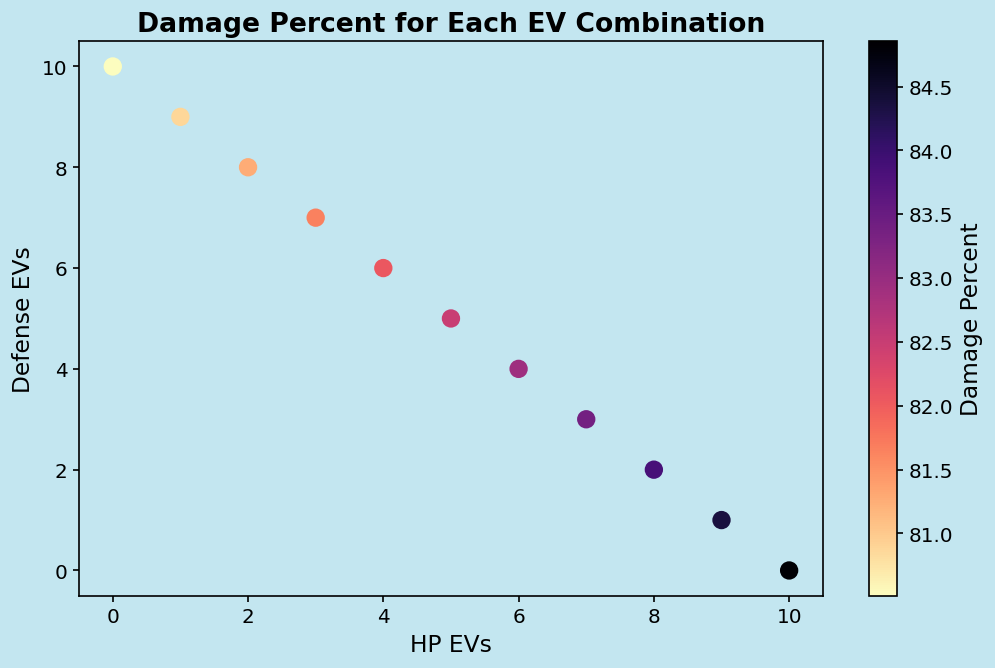

In [16]:

# Constants
power = 80*2
atk = 182
base_health = 170
base_defense = 85
level = 50
total_evs = 10

# Define the damage_percent function
def damage_percent(defense_evs, health_evs):
    if defense_evs + health_evs > total_evs:  # Constraint check
        return 0  # Invalid solution
    return ((( (2*level/5 + 2) * power * (atk / (base_defense + defense_evs)) ) / 50) + 2 ) / (base_health + health_evs) * 100

# Generate all valid combinations of hp_evs and def_evs
ev_combinations = [
    (hp, total_evs - hp)
    for hp in range(0, min(32, total_evs) + 1)
    if total_evs - hp <= 32
]

# Calculate damage_percent for each combination
results = []
for hp, defense in ev_combinations:
    hp_percent = damage_percent(defense, hp)
    results.append((hp, defense, hp_percent))

# Find the optimal combination
optimal_combination = max(results, key=lambda x: x[2])  # Maximize damage_percent
optimal_hp, optimal_defense, max_damage_percent = optimal_combination

print(f"Optimal HP EVs: {optimal_hp}")
print(f"Optimal Defense EVs: {optimal_defense}")
print(f"Maximum Damage Percent: {max_damage_percent}")

# Plot the results
hp_evs = [r[0] for r in results]
def_evs = [r[1] for r in results]
damage_percents = [r[2] for r in results]

plt.figure(figsize=(10, 6))
plt.scatter(hp_evs, def_evs, c=damage_percents, cmap='magma_r', s=100)
plt.colorbar(label='Damage Percent')
plt.xlabel('HP EVs')
plt.ylabel('Defense EVs')
plt.title('Damage Percent for Each EV Combination')
plt.show()

In [17]:
# import matplotlib.pyplot as plt
# import numpy as np

# # Create a sample gradient
# gradient = np.linspace(0, 1, 256).reshape(1, -1)

# # Get all colormaps (correct way for newer matplotlib)
# cmaps = sorted(plt.colormaps())

# # Display a subset of them
# fig, axes = plt.subplots(nrows=len(cmaps)//5, ncols=5, figsize=(15, 20))
# axes = axes.flatten()

# for idx, cmap_name in enumerate(cmaps[:len(axes)]):
#     axes[idx].imshow(gradient, aspect='auto', cmap=cmap_name)
#     axes[idx].set_title(cmap_name, fontsize=8)
#     axes[idx].axis('off')

# plt.tight_layout()
# plt.show()

In [18]:
def optimize_damage_percent(base_health, base_defense, total_evs, def_mult=1, atk=150, power=100, level=50):
    """
    Optimizes Damage Percent based on given constants and EV constraints.

    Args:
        power (int): Power of the move.
        atk (int): Attack stat.
        base_health (int): Base health stat.
        base_defense (int): Base defense stat.
        level (int): Level of the Pokémon.
        total_evs (int): Total EVs available to distribute.

    Returns:
        dict: A dictionary containing the optimal HP EVs, Defense EVs, maximum Damage Percent, and a plot.
    """
    # Define the damage_percent function
    def damage_percent(defense_evs, health_evs):
        
        calculated_health = base_health + health_evs + 75
        calculated_defense = math.floor((base_defense + defense_evs + 20) * def_mult)

        if defense_evs + health_evs > total_evs:  # Constraint check
            return 0  # Invalid solution
        return ((( (2 * level / 5 + 2) * power * (atk / calculated_defense) ) / 50) + 2 ) / (calculated_health) * 100

    # Generate all valid combinations of hp_evs and def_evs
    ev_combinations = [
        (hp, total_evs - hp)
        for hp in range(0, min(32, total_evs) + 1)
        if total_evs - hp <= 32
    ]

    # Calculate damage_percent for each combination
    results = []
    for hp, defense in ev_combinations:
        hp_percent = damage_percent(defense, hp)
        results.append((hp, defense, hp_percent))

    # Find the optimal combination
    optimal_combination = min(results, key=lambda x: x[2])  # Minimize damage_percent
    optimal_hp, optimal_defense, min_damage_percent = optimal_combination

    # Print the optimal results
    print(f"Optimal HP EVs: {optimal_hp}")
    print(f"Optimal Defense EVs: {optimal_defense}")
    print(f"Minimum Damage Percent: {min_damage_percent}")

    # Plot the results
    hp_evs = [r[0] for r in results]
    def_evs = [r[1] for r in results]
    damage_percents = [r[2] for r in results]

    plt.figure(figsize=(10, 6))
    plt.scatter(hp_evs, def_evs, c=damage_percents, cmap='magma_r', s=100)
    plt.colorbar(label='Damage Percent')
    plt.xlabel('HP EVs')
    plt.ylabel('Defense EVs')
    plt.title('Damage Percent for Each EV Combination')
    plt.show()

    # Return the results as a dictionary
    return {
        "optimal_hp_evs": optimal_hp,
        "optimal_defense_evs": optimal_defense,
        "min_damage_percent": min_damage_percent
    }

# HP = Base + StatPoints + 75
# OtherStat = lower( (Base + StatPoints + 20) * Allignment(1.2/0.8/1) )

Optimal HP EVs: 20
Optimal Defense EVs: 30
Minimum Damage Percent: 45.294117647058826


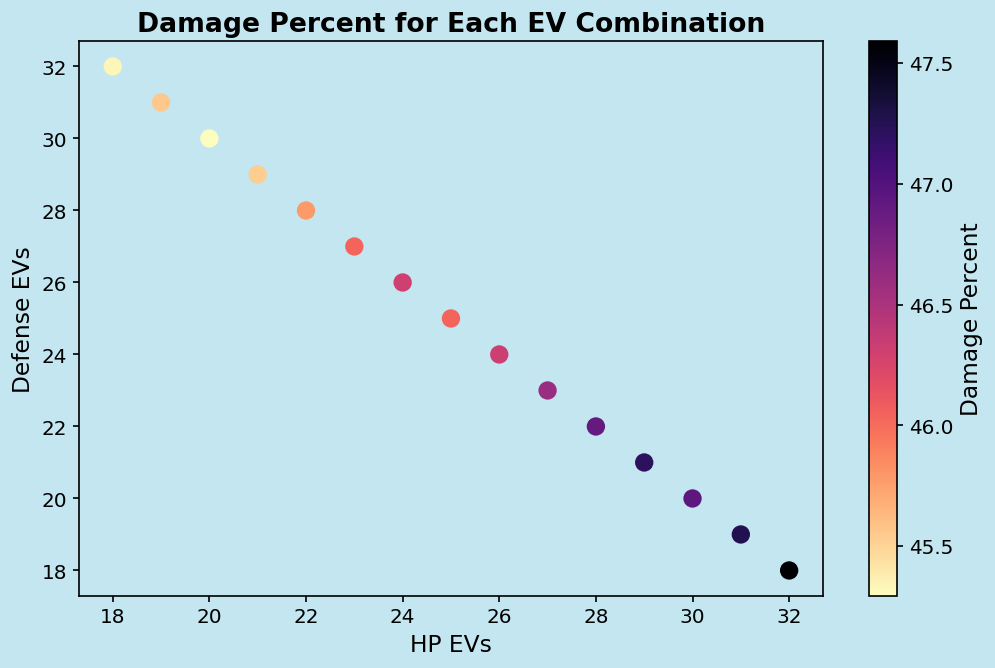

{'optimal_hp_evs': 20, 'optimal_defense_evs': 30, 'min_damage_percent': 45.294117647058826}


In [19]:
#simplified formula for Damage Percent:
#((( 22 / calculated_defense ) / 50) + 2 ) / (calculated_health) * 100

# Example usage
results = optimize_damage_percent(
    base_health=75,
    base_defense=60,
    total_evs=50,
    def_mult = 0.8
)

print(results)

In [20]:


starting_base_health = 95
starting_base_defense = 140
total_evs = 40
atk = 182
power = 160
level = 50
bonus = 1.5


def interactive_heatmap_with_widgets():
    def plot_heatmap(base_health, base_defense, total_evs, def_mult):
        # Define the damage_percent function
        def damage_percent(defense_evs, health_evs):
            calculated_health = base_health + health_evs + 75
            calculated_defense = math.floor((base_defense + defense_evs + 20) * def_mult)
            if (defense_evs + health_evs) > total_evs:  # Constraint check
                return 0  # Invalid solution
            return ((( ( (2 * level / 5) + 2) * power * ( (atk * bonus) / calculated_defense) ) / 50) + 2 ) / (calculated_health) * 100
        
       

        # Create a grid for HP EVs and Defense EVs
        hp_evs_range = np.arange(0, 33)  # EVs from 0 to 32
        def_evs_range = np.arange(0, 33)
        heatmap_data = np.zeros((len(hp_evs_range), len(def_evs_range)))

        # Calculate damage_percent for each combination
        for i, hp in enumerate(hp_evs_range):
            for j, defense in enumerate(def_evs_range):
                heatmap_data[i, j] = damage_percent(defense, hp)

        # Flip the heatmap data along the y-axis to match the reversed y-axis labels
        # heatmap_df = pd.DataFrame(heatmap_data)
        # print(heatmap_df)

        # heatmap_data = np.flipud(heatmap_data)

        # heatmap_df = pd.DataFrame(heatmap_data)
        # print(heatmap_df)

        # Find the minimum damage_percent that is not zero and its coordinates
        # Mask zero values in the heatmap data
        masked_heatmap = np.ma.masked_where(heatmap_data == 0, heatmap_data)

        flipped_heatmap_data = np.flipud(heatmap_data)

        # Find the index of the minimum non-zero value
        min_index = np.unravel_index(np.ma.argmin(masked_heatmap), flipped_heatmap_data.shape)

        # Extract the optimal EVs
        optimal_hp_evs = hp_evs_range[min_index[0]]
        optimal_defense_evs = def_evs_range[min_index[1]]
        optimal_hp_evs = hp_evs_range[min_index[0]]
        optimal_defense_evs = def_evs_range[min_index[1]]
        min_damage_percent = heatmap_data[min_index]

        print(f"Optimal HP EVs: {optimal_hp_evs}")
        print(f"Optimal Defense EVs: {optimal_defense_evs}")
        print(f"Minimum Damage Percent: {min_damage_percent}")

        #flip optimal_hp_evs to match the flipped y-axis
        optimal_hp_evs = 32 - optimal_hp_evs

        # Create a custom colormap
        cmap = sns.color_palette("magma_r", as_cmap=True)
        cmap_with_grey = ListedColormap(list(cmap(np.linspace(0, 1, 256))))

        # Mask zero values
        mask = flipped_heatmap_data == 0

        # Create the heat map
        plt.figure(figsize=(12, 8))
        sns.heatmap(
            flipped_heatmap_data,
            xticklabels=def_evs_range,  # Defense EVs on x-axis
            yticklabels=hp_evs_range[::-1],  # Reverse HP EVs for correct orientation
            cmap=cmap_with_grey,
            mask=mask,
            cbar_kws={'label': 'Damage Percent'}
        )
        plt.xlabel("Defense EVs")
        plt.ylabel("HP EVs")
        plt.title("Damage Percent Heat Map")

        # Overlay the total_evs constraint line
        # Overlay the total_evs constraint line
        hp_evs = np.arange(0, min(33, total_evs + 1))
        def_evs = total_evs - hp_evs

        #plt.plot(def_evs, hp_evs[::-1], color="red", label="Total EVs Constraint")  # Reverse hp_evs for flipped y-axis
        plt.scatter(
            optimal_defense_evs+.5, 
            optimal_hp_evs+.5,
            color="white", 
            edgecolor="black", 
            s=100, 
            label="Optimal Point",
            linewidths=2.5,
        )
        plt.legend()

        # Show the plot
        plt.show()

    # Interactive sliders for parameters
    interact(
        plot_heatmap,
        base_health=IntSlider(value=starting_base_health, min=49, max=120, step=1, description="Base Health"),
        base_defense=IntSlider(value=starting_base_defense, min=40, max=150, step=1, description="Base Defense"),
        total_evs=IntSlider(value=total_evs, min=0, max=64, step=1, description="Total EVs"),
        def_mult=FloatSlider(value=1.0, min=0.8, max=1.2, step=0.2, description="Defense Multiplier")
    )

# Call the function to enable interactivity
interactive_heatmap_with_widgets()

interactive(children=(IntSlider(value=95, description='Base Health', max=120, min=49), IntSlider(value=140, de…

In [21]:
%%manim -qm DamageHeatmap

class DamageHeatmap(Scene):
    def construct(self):
        starting_base_health = 95
        starting_base_defense = 140
        total_evs = 40
        atk = 182
        power = 160
        level = 50
        bonus = 1.5
        def_mult = 1.0

        grid_size = 32
        cell_size = 0.35
        step = 1

        def damage_percent(defense_evs, health_evs):
            calculated_health = starting_base_health + health_evs + 75
            calculated_defense = math.floor((starting_base_defense + defense_evs + 20) * def_mult)
            if (defense_evs + health_evs) > total_evs:
                return 0
            return ((((2 * level / 5) + 2) * power * ((atk * bonus) / calculated_defense)) / 50 + 2) / calculated_health * 100

        values = [[damage_percent(j * step, i * step) for j in range(grid_size)] for i in range(grid_size)]
        valid = [v for row in values for v in row if v > 0]
        max_val = max(valid)
        min_val = min(valid)

        min_positions = []
        for i in range(grid_size):
            for j in range(grid_size):
                if values[i][j] == min_val:
                    min_positions.append((i, j))

        plot_axes = Axes(
            x_range=[0, grid_size, 4],
            y_range=[0, grid_size, 4],
            x_length=6.0,
            y_length=6.0,
            axis_config={
                "color": BLACK,
                "include_numbers": True,
                "font_size": 18,
                "label_direction": DOWN,
                "decimal_number_config": {"num_decimal_places": 0, "color": BLACK},
            },
            tips=False,
        )

        cells = VGroup()
        cell_lookup = {}
        grid_origin = plot_axes.c2p(0.5, 0.5)
        x_step = plot_axes.x_length / grid_size
        y_step = plot_axes.y_length / grid_size

        for i in range(grid_size):
            for j in range(grid_size):
                val = values[i][j]
                if val > 0:
                    t = (val - min_val) / (max_val - min_val) if max_val > min_val else 0.5
                    color = interpolate_color(RED_A, MAROON_E, t)
                    sq = Square(side_length=min(x_step, y_step), fill_color=color, fill_opacity=1, stroke_width=0.3)
                else:
                    sq = Square(side_length=min(x_step, y_step), fill_opacity=0, stroke_width=0)
                sq.move_to(grid_origin + np.array([j * x_step, i * y_step, 0]))
                cells.add(sq)
                cell_lookup[(i, j)] = sq

        title = Text("Damage % Heatmap", font_size=30)
        x_label = Text("Defense EVs", font_size=24)
        y_label = Text("HP EVs", font_size=24).rotate(PI / 2)

        title.next_to(plot_axes, UP, buff=0.35)
        x_label.next_to(plot_axes, DOWN, buff=0.35)
        y_label.next_to(plot_axes, LEFT, buff=0.45)

        layout = VGroup(plot_axes, cells, title, x_label, y_label)
        layout.scale_to_fit_width(config.frame_width * 0.9)
        layout.scale_to_fit_height(config.frame_height * 0.84)
        layout.move_to(ORIGIN)

        cells_sorted = sorted(cells, key=lambda cell: cell.get_center()[0] + cell.get_center()[1])

        self.add(plot_axes, title, x_label, y_label)
        self.play(LaggedStart(*[FadeIn(c) for c in cells_sorted], lag_ratio=0.01), run_time=3)

        markers = VGroup()
        labels = VGroup()
        for i, j in min_positions:
            cell = cell_lookup[(i, j)]
            markers.add(SurroundingRectangle(cell, color=BLACK, buff=0.02, stroke_width=3))
            labels.add(Text(f"{min_val:.1f}%", font_size=14, color=BLACK).next_to(cell, UP, buff=0.04))

        self.play(Create(markers), FadeIn(labels))
        self.wait(2)


Manim Community v0.20.1

In [22]:
def damage_percent(defense_evs, health_evs, base_health, base_defense, total_evs, def_mult=1, atk=150, power=100, level=50, bonus=[1]):
    #print all values
    #print(f"Defense EVs: {defense_evs}, Health EVs: {health_evs}, Base Health: {base_health}, Base Defense: {base_defense}, Total EVs: {total_evs}, Defense Multiplier: {def_mult}, Attack: {atk}, Power: {power}, Level: {level}, Bonus: {bonus}")
    calculated_health = base_health + health_evs + 75
    calculated_defense = math.floor((base_defense + defense_evs + 20) * def_mult)
    if (defense_evs + health_evs) > total_evs:  # Constraint check
        return 0  # Invalid solution
    raw_damage = math.floor((( ( (2 * level / 5) + 2) * power * ( (atk) / calculated_defense) ) / 50) + 2 )

    for b in bonus:
        raw_damage = round(raw_damage * b)

    #print(f" Raw Damage: {raw_damage} / Calculated Health: {calculated_health}, Calculated Defense: {calculated_defense}, Damage Percent: {raw_damage / calculated_health * 100}%")
    return raw_damage / calculated_health * 100

    # print(((( ( (2 * level / 5) + 2) * power * ( (atk * bonus) / calculated_defense) ) / 50) + 2 ))
    # return ((( ( (2 * level / 5) + 2) * power * ( (atk * bonus) / calculated_defense) ) / 50) + 2 ) / (calculated_health) * 100

In [23]:
#so I have a set of attacks that I want to optimize for, I think I want checkpoints for each attack

#Targets x Parental Bond x Weather x GlaiveRush x Critical x random x STAB x Type x Burn x other x ZMove x TeraShield

attacks = [
   # {"name": "Power Gem", "power": 80, "atk": 182, "bonus": [1.5,2], "PhySpec": "Special", "evs": []},
    {"name": "Dire Claw", "power": 80, "atk": 200, "bonus": [1.5, 2], "PhySpec": "Physical", "evs": []},
    #{"name": "Iron Head", "power": 80, "atk": 205, "bonus": [1.5,2], "PhySpec": "Physical", "evs": []},
    #{"name": "Flash Cannon", "power": 80, "atk": 194, "bonus": [1.5,2], "PhySpec": "Special", "evs": []},
    #{"name": "Last Respects", "power": 150, "atk": 180, "bonus": [2], "PhySpec": "Physical", "evs": []},
    {"name": "Hyper Voice", "power": 90*1.2*1.2, "atk": 178, "bonus": [0.75, 1.5, 2], "PhySpec": "Special", "evs": []}
]

#defense = {"name": "Aerodactyl", "base_health": 80, "base_defense": 65, "base_special_defense": 75}
#defense = {"name": "Mega Altaria", "base_health": 75, "base_defense": 110, "base_special_defense": 105}
defense = {"name": "Decidueye-Hisui", "base_health": 88, "base_defense": 80, "base_special_defense": 95}


starting_base_health = defense['base_health']
starting_base_defense = defense['base_defense']
starting_base_special_defense = defense['base_special_defense']
level = 50

evs_map = np.zeros((33, 33))

#TODO: If it fails to optimize remove an attack and try again?

attackN = 0
for a in attacks:
    print(f"Optimizing for {a['name']}...")
    print(a)
    for i, hp in enumerate(np.arange(0, 33)):
        for j, defense in enumerate(np.arange(0, 33)):
            base_defense = starting_base_defense if a['PhySpec'] == "Physical" else starting_base_special_defense
            evs_map[i, j] = damage_percent(defense_evs = defense, health_evs = hp, base_health = starting_base_health, base_defense = base_defense, total_evs = 64, def_mult = 1, atk = a['atk'], power = a['power'], level = level, bonus = a['bonus'])


            attacks[attackN]['evs'].append((hp, defense, evs_map[i, j]))
            # if evs_map[i, j] != 0 and evs_map[i, j] < 100:
            #     attacks[attackN]['evs'].append((hp, defense, evs_map[i, j]))
            # else:
            #     attacks[attackN]['evs'].append((hp, defense, 0))
    attackN += 1

Optimizing for Dire Claw...
{'name': 'Dire Claw', 'power': 80, 'atk': 200, 'bonus': [1.5, 2], 'PhySpec': 'Physical', 'evs': []}
Optimizing for Hyper Voice...
{'name': 'Hyper Voice', 'power': 129.6, 'atk': 178, 'bonus': [0.75, 1.5, 2], 'PhySpec': 'Special', 'evs': []}


In [24]:
attacks[1]['evs']
#attacks[1]['evs'][-70:]

[(np.int64(0), np.int64(0), np.float64(125.15337423312884)),
 (np.int64(0), np.int64(1), np.float64(122.69938650306749)),
 (np.int64(0), np.int64(2), np.float64(121.47239263803682)),
 (np.int64(0), np.int64(3), np.float64(121.47239263803682)),
 (np.int64(0), np.int64(4), np.float64(120.24539877300613)),
 (np.int64(0), np.int64(5), np.float64(117.79141104294479)),
 (np.int64(0), np.int64(6), np.float64(117.79141104294479)),
 (np.int64(0), np.int64(7), np.float64(117.79141104294479)),
 (np.int64(0), np.int64(8), np.float64(115.33742331288343)),
 (np.int64(0), np.int64(9), np.float64(114.11042944785277)),
 (np.int64(0), np.int64(10), np.float64(114.11042944785277)),
 (np.int64(0), np.int64(11), np.float64(114.11042944785277)),
 (np.int64(0), np.int64(12), np.float64(112.88343558282207)),
 (np.int64(0), np.int64(13), np.float64(112.88343558282207)),
 (np.int64(0), np.int64(14), np.float64(110.42944785276075)),
 (np.int64(0), np.int64(15), np.float64(110.42944785276075)),
 (np.int64(0), np.

In [25]:
#attach the lowest defense percent and lowest special defense percent to each unique hp evs value for each attack

#create dict with a evs key for 1-32
optimized_evs = {hp: {"defense": None, "special_defense": None} for hp in range(33)}

for a in attacks:
    print(a)
    #for each hp ev value get the lowest defense evs and lowest special defense evs and attach to optimized_evs dict
    for hp in range(33):
        #print(a['evs'])

                #gets ev1 and 2 for corrosponding hp
        pairs = [(ev[1], ev[2]) for ev in a['evs'] if ev[0] == hp and ev[2] is not None]
        if not pairs:
            continue

                    #gets evs and damage for all pairs where dmg < 100
        under_100 = [(d_ev, dmg) for d_ev, dmg in pairs if dmg < 100]
        #runs min on under_100 or pairs at [0]
        if under_100:
            min_defense_evs, chosen_damage = min(under_100, key=lambda x: x[0])
        else:
            min_defense_evs, chosen_damage = min(pairs, key=lambda x: x[0])

        if a['PhySpec'] == "Physical":
            if optimized_evs[hp]['defense'] is None or min_defense_evs > optimized_evs[hp]['defense']:
                optimized_evs[hp]['defense'] = min_defense_evs
                optimized_evs[hp]['defense_percent'] = chosen_damage
        else:
            if optimized_evs[hp]['special_defense'] is None or min_defense_evs > optimized_evs[hp]['special_defense']:
                optimized_evs[hp]['special_defense'] = min_defense_evs
                optimized_evs[hp]['special_defense_percent'] = chosen_damage

# for oe in optimized_evs:
#     #if sum of hp evs, def evs, spD evs is less than or equal to 66 keep
#     if optimized_evs[oe]['defense'] is not None and optimized_evs[oe]['special_defense'] is not None:
#         if oe + optimized_evs[oe]['defense'] + optimized_evs[oe]['special_defense'] <= 66:
#             optimized_evs[oe]['total'] = oe + optimized_evs[oe]['defense'] + optimized_evs[oe]['special_defense']

{'name': 'Dire Claw', 'power': 80, 'atk': 200, 'bonus': [1.5, 2], 'PhySpec': 'Physical', 'evs': [(np.int64(0), np.int64(0), np.float64(132.51533742331287)), (np.int64(0), np.int64(1), np.float64(130.06134969325154)), (np.int64(0), np.int64(2), np.float64(130.06134969325154)), (np.int64(0), np.int64(3), np.float64(128.83435582822085)), (np.int64(0), np.int64(4), np.float64(127.60736196319019)), (np.int64(0), np.int64(5), np.float64(127.60736196319019)), (np.int64(0), np.int64(6), np.float64(125.15337423312884)), (np.int64(0), np.int64(7), np.float64(122.69938650306749)), (np.int64(0), np.int64(8), np.float64(122.69938650306749)), (np.int64(0), np.int64(9), np.float64(121.47239263803682)), (np.int64(0), np.int64(10), np.float64(121.47239263803682)), (np.int64(0), np.int64(11), np.float64(120.24539877300613)), (np.int64(0), np.int64(12), np.float64(117.79141104294479)), (np.int64(0), np.int64(13), np.float64(117.79141104294479)), (np.int64(0), np.int64(14), np.float64(115.33742331288343))

In [26]:
#for each set of optimized evs find the one with the least evs total (hp, def, spD) and attach it to optimized evs
for hp in range(33):
    if optimized_evs[hp]['defense'] is None or optimized_evs[hp]['special_defense'] is None or optimized_evs[hp]['defense_percent'] >= 100 or optimized_evs[hp]['special_defense_percent'] >= 100:
        #remove key
        del optimized_evs[hp]
        continue
    defense_evs = optimized_evs[hp]['defense']
    special_defense_evs = optimized_evs[hp]['special_defense']
    total_evs = hp + defense_evs + special_defense_evs
    optimized_evs[hp]['total_evs'] = total_evs

In [27]:
#print min total evs and corresponding hp, defense, and special defense evs
min_total_evs = min([optimized_evs[hp]['total_evs'] for hp in optimized_evs])
best_evs = None
for hp in optimized_evs:
    if optimized_evs[hp]['total_evs'] == min_total_evs:
        print(f"Optimal HP EVs: {hp}, Optimal Defense EVs: {optimized_evs[hp]['defense']}, Optimal Special Defense EVs: {optimized_evs[hp]['special_defense']}, Total EVs: {optimized_evs[hp]['total_evs']}")
        best_evs = optimized_evs[hp]

Optimal HP EVs: 30, Optimal Defense EVs: 12, Optimal Special Defense EVs: 5, Total EVs: 47


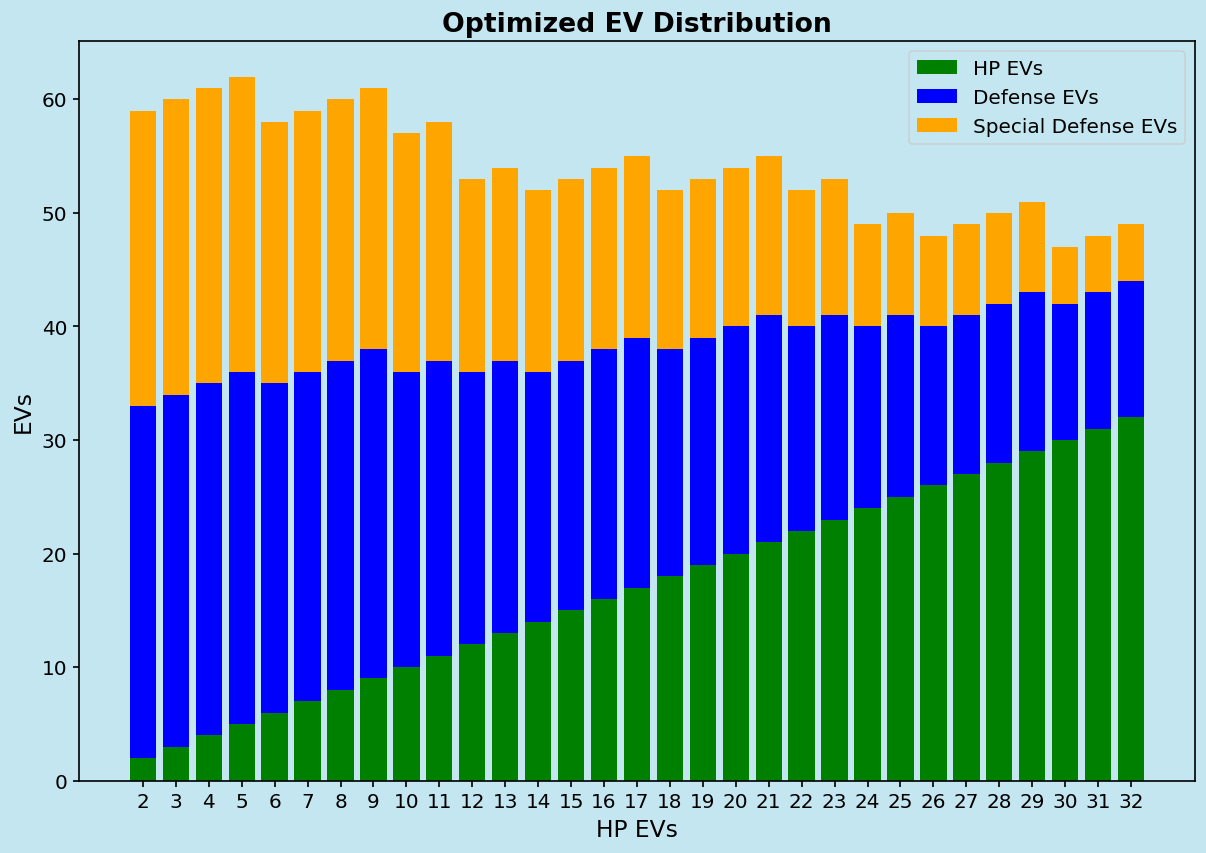

In [28]:
#graph optimized_evs in a stacked bar chart with total evs on the y axis, with different colors for hp, defense and special defense evs
hp_evs = list(optimized_evs.keys())
defense_evs = [optimized_evs[hp]['defense'] for hp in optimized_evs]
special_defense_evs = [optimized_evs[hp]['special_defense'] for hp in optimized_evs]
total_evs = [optimized_evs[hp]['total_evs'] for hp in optimized_evs]

plt.figure(figsize=(12, 8))
plt.bar(hp_evs, hp_evs, color='green', label='HP EVs')
plt.bar(hp_evs, defense_evs, bottom=hp_evs, color='blue', label='Defense EVs')
plt.bar(hp_evs, special_defense_evs, bottom=np.add(hp_evs, defense_evs), color='orange', label='Special Defense EVs')
plt.xlabel('HP EVs')
plt.xticks(hp_evs)
plt.ylabel('EVs')
plt.title('Optimized EV Distribution')
plt.legend()
plt.show()



In [29]:
%%manim -qm StackedEVBarChart

class StackedEVBarChart(Scene):
    def construct(self):
        
        # Extract data from optimized_evs
        hp_evs = list(optimized_evs.keys())
        defense_evs_list = [optimized_evs[hp]['defense'] for hp in hp_evs]
        special_defense_evs_list = [optimized_evs[hp]['special_defense'] for hp in hp_evs]
        total_evs_list = [hp + defense + special_defense for hp, defense, special_defense in zip(hp_evs, defense_evs_list, special_defense_evs_list)]
        
        max_total = max(total_evs_list)
        
        # Create axes
        ax = Axes(
            x_range=[0, max(hp_evs), 4],
            y_range=[0, max_total + 5, 5],
            x_length=10,
            y_length=6,
            axis_config={"include_numbers": True,
                        "include_ticks": True,
                        "color": BLACK,
                        "decimal_number_config": {"num_decimal_places": 0, "color": BLACK},
                        },
            tips=False,
        )

        ax.shift(RIGHT * 0.5)
        
        # Create title and labels
        title = Text("Optimized EV Distribution - Stacked Bars", font_size=28, font='Arial')
        x_label = Text("HP EVs", font_size=20).next_to(ax.x_axis, DOWN, buff=0.3)
        y_label = Text("Total EVs", font_size=20).next_to(ax.y_axis, LEFT, buff=0.3).rotate(PI/2)
        
        title.to_edge(UP, buff=0.3)
        
        # Create legend
        legend_items = VGroup(
            VGroup(Rectangle(width=0.2, height=0.2, fill_color=GREEN, fill_opacity=1, stroke_color=BLACK, stroke_width=0.5), Text("HP EVs", font_size=14, color=BLACK)),
            VGroup(Rectangle(width=0.2, height=0.2, fill_color=BLUE, fill_opacity=1, stroke_color=BLACK, stroke_width=0.5), Text("Defense EVs", font_size=14, color=BLACK)),
            VGroup(Rectangle(width=0.2, height=0.2, fill_color=ORANGE, fill_opacity=1, stroke_color=BLACK, stroke_width=0.5), Text("Sp.Def EVs", font_size=14, color=BLACK)),
        )
        for item in legend_items:
            item.arrange(RIGHT, buff=0.15)
        legend_items.arrange(DOWN, buff=0.2, aligned_edge=LEFT)
        legend_items.to_corner(UR, buff=0.3)
        
        # Calculate bar width in scene coordinates
        # Height scale factor: axis plot area height / max y value
        height_scale = ax.y_length / (max_total + 5)
        
        # Create stacked bars - separated by segment type
        hp_bars = VGroup()
        defense_bars = VGroup()
        sp_def_bars = VGroup()
        
        for i, hp in enumerate(hp_evs):
            x_pos = hp
            hp_height = hp_evs[i]
            defense_height = defense_evs_list[i]
            sp_def_height = special_defense_evs_list[i]
            
            # HP bar (green)
            hp_bar_height = hp_height * height_scale
            hp_bar = Rectangle(
                width=0.2,
                height=hp_bar_height,
                fill_color=GREEN,
                fill_opacity=0.9,
                stroke_width=1,
                stroke_color=BLACK
            )
            hp_bar.move_to(ax.c2p(x_pos, hp_height/2))
            hp_bars.add(hp_bar)
            
            # Defense bar (blue)
            if defense_height > 0:
                defense_bar_height = defense_height * height_scale
                defense_bar = Rectangle(
                    width=0.2,
                    height=defense_bar_height,
                    fill_color=PURPLE,
                    fill_opacity=0.9,
                    stroke_width=1,
                    stroke_color=BLACK
                )
                defense_bar.move_to(ax.c2p(x_pos, hp_height + defense_height/2))
                defense_bars.add(defense_bar)
            
            # Special Defense bar (orange)
            if sp_def_height > 0:
                sp_def_bar_height = sp_def_height * height_scale
                sp_def_bar = Rectangle(
                    width=0.2,
                    height=sp_def_bar_height,
                    fill_color=ORANGE,
                    fill_opacity=0.9,
                    stroke_width=1,
                    stroke_color=BLACK
                )
                sp_def_bar.move_to(ax.c2p(x_pos, hp_height + defense_height + sp_def_height/2))
                sp_def_bars.add(sp_def_bar)
        
        # Add axes and labels
        self.add(ax, title, x_label, y_label, legend_items)
        
        # Animate bars growing column by column: for each HP value, grow HP -> Defense -> Sp.Def sequentially
        for i in range(len(hp_evs)):
            # Grow HP bar
            if i < len(hp_bars):
                self.play(GrowFromEdge(hp_bars[i], DOWN), run_time=0.1)
            # Then grow Defense bar
            if i < len(defense_bars):
                self.play(GrowFromEdge(defense_bars[i], DOWN), run_time=0.1)
            # Then grow Sp.Def bar
            if i < len(sp_def_bars):
                self.play(GrowFromEdge(sp_def_bars[i], DOWN), run_time=0.1)
        
        self.wait(2)

Manim Community v0.20.1

In [30]:
best_evs['hp'] = best_evs['total_evs'] - best_evs['defense'] - best_evs['special_defense']
best_evs

{'defense': np.int64(12),
 'special_defense': np.int64(5),
 'defense_percent': np.float64(99.48186528497409),
 'special_defense_percent': np.float64(99.48186528497409),
 'total_evs': np.int64(47),
 'hp': np.int64(30)}

In [31]:
print(f"HP: {best_evs['hp']}, Defense: {best_evs['defense']}, Special Defense: {best_evs['special_defense']}, Total EVs: {best_evs['total_evs']}")
for a in attacks:
    if a['PhySpec'] == "Physical":
        #get the matching hp and def (x, x, 0) tuple from a['evs'] where x is the hp evs and def evs from best_evs
        for ev in a['evs']:
            if ev[0] == best_evs['hp'] and ev[1] == best_evs['defense']:
                print(f"{a['name']} - {ev[2]:.2f}%")
    else:
        for ev in a['evs']:
            if ev[0] == best_evs['hp'] and ev[1] == best_evs['special_defense']:
                print(f"{a['name']} - {ev[2]:.2f}%")

HP: 30, Defense: 12, Special Defense: 5, Total EVs: 47
Dire Claw - 99.48%
Hyper Voice - 99.48%


So I want do make a set of damage amounts, it shouldn't be an issue since the defenses can stay consistent. I want to figure out how "bulky" a pokemon is. So we are EVing to live a certain hit, which can give us a couple sets of evs. Which one is the best? Is it always max hp?
We could try hp - 16, def/spd - 10.
Would it change based on damage? So does 10 damage favour health more?

So we have a couple variables. HP, Def, damage of attack, damage taken
I could merge hp and def to just be the minimum

Could I also look into minimizing damage with a set of possible evs?
Could probably brute force knowing all attacks

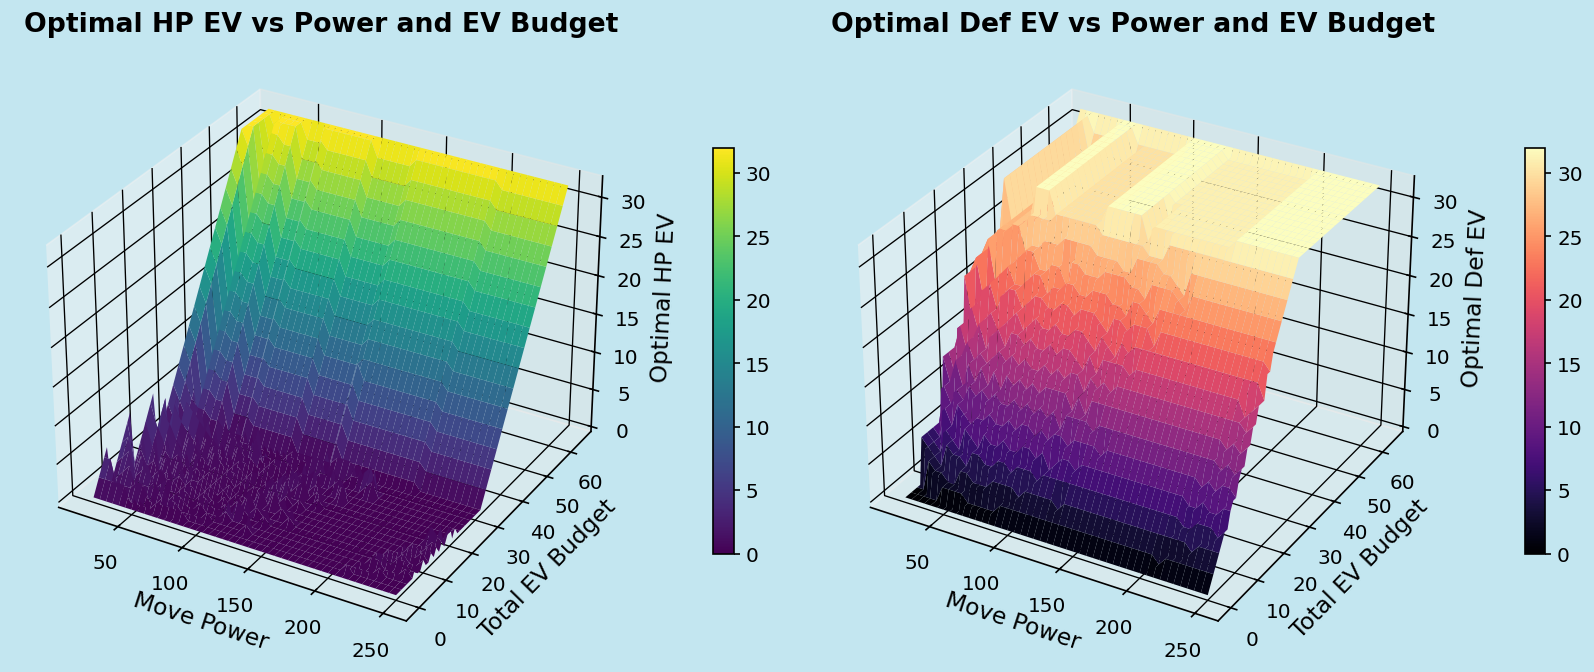

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# --- inputs you can tune ---
base_health = starting_base_health
base_defense = starting_base_defense      # use starting_base_special_defense for SpD view
atk = 180
level = 50
def_mult = 1.0
bonus = [1.0]
power_values = np.arange(20, 251, 5)      # "damage axis"
total_evs_values = np.arange(0, 65)       # EV budget axis (0..64)

# outputs
opt_hp = np.full((len(power_values), len(total_evs_values)), np.nan)
opt_def = np.full((len(power_values), len(total_evs_values)), np.nan)
min_dmg = np.full((len(power_values), len(total_evs_values)), np.nan)

for i, power in enumerate(power_values):
    for j, total_evs in enumerate(total_evs_values):
        best = None  # (damage%, hp, def)
        max_hp = min(32, total_evs)

        for hp in range(max_hp + 1):
            defense = total_evs - hp
            if defense > 32:
                continue

            d = damage_percent(
                defense_evs=defense,
                health_evs=hp,
                base_health=base_health,
                base_defense=base_defense,
                total_evs=total_evs,
                def_mult=def_mult,
                atk=atk,
                power=power,
                level=level,
                bonus=bonus
            )

            # minimize damage; tie-break toward balanced split (max min(hp,def))
            if (
                best is None
                or d < best[0] - 1e-12
                or (abs(d - best[0]) <= 1e-12 and min(hp, defense) > min(best[1], best[2]))
            ):
                best = (d, hp, defense)

        if best is not None:
            min_dmg[i, j] = best[0]
            opt_hp[i, j] = best[1]
            opt_def[i, j] = best[2]

# mesh for 3D surfaces
X, Y = np.meshgrid(total_evs_values, power_values)

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(121, projection="3d")
surf1 = ax1.plot_surface(Y, X, opt_hp, cmap="viridis", edgecolor="none")
ax1.set_title("Optimal HP EV vs Power and EV Budget")
ax1.set_xlabel("Move Power")
ax1.set_ylabel("Total EV Budget")
ax1.set_zlabel("Optimal HP EV")
fig.colorbar(surf1, ax=ax1, shrink=0.6, pad=0.1)

ax2 = fig.add_subplot(122, projection="3d")
surf2 = ax2.plot_surface(Y, X, opt_def, cmap="magma", edgecolor="none")
ax2.set_title("Optimal Def EV vs Power and EV Budget")
ax2.set_xlabel("Move Power")
ax2.set_ylabel("Total EV Budget")
ax2.set_zlabel("Optimal Def EV")
fig.colorbar(surf2, ax=ax2, shrink=0.6, pad=0.1)

plt.tight_layout()
plt.show()

Optimal HP EVs: 32
Optimal Defense EVs: 18
Minimum Damage Percent: 1.098901098901099


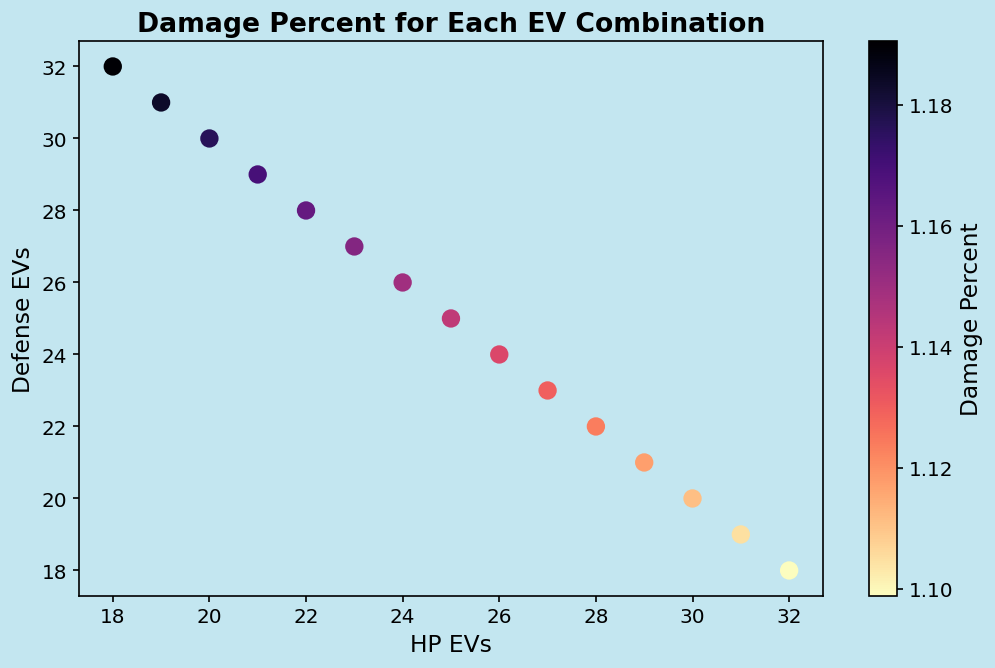

{'optimal_hp_evs': 32, 'optimal_defense_evs': 18, 'min_damage_percent': 1.098901098901099}
Optimal HP EVs: 32
Optimal Defense EVs: 18
Minimum Damage Percent: 1.3455931823278762


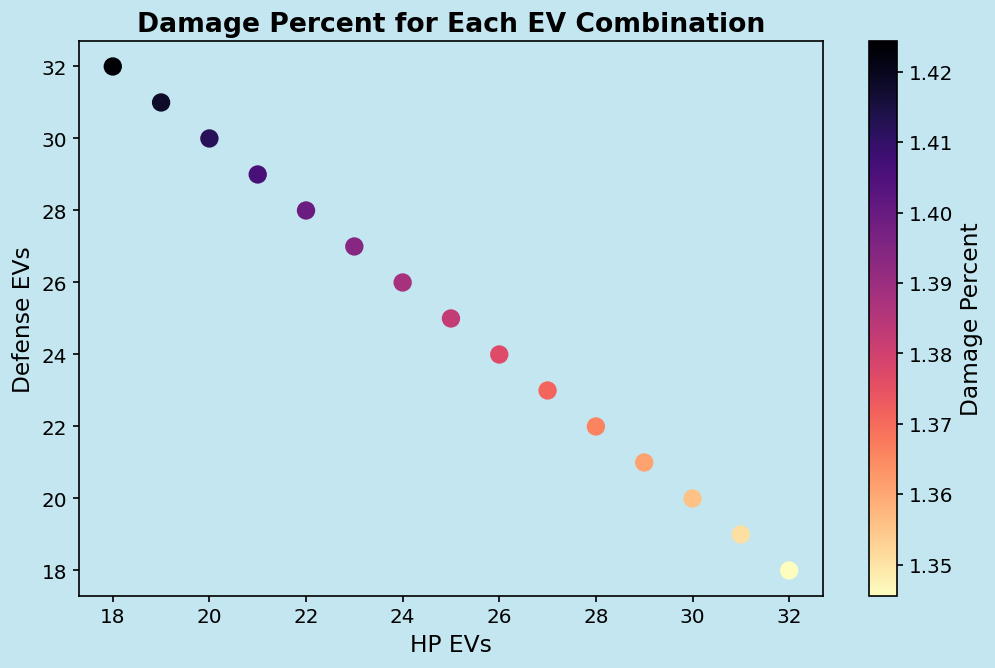

{'optimal_hp_evs': 32, 'optimal_defense_evs': 18, 'min_damage_percent': 1.3455931823278762}
Optimal HP EVs: 32
Optimal Defense EVs: 18
Minimum Damage Percent: 1.5922852657546536


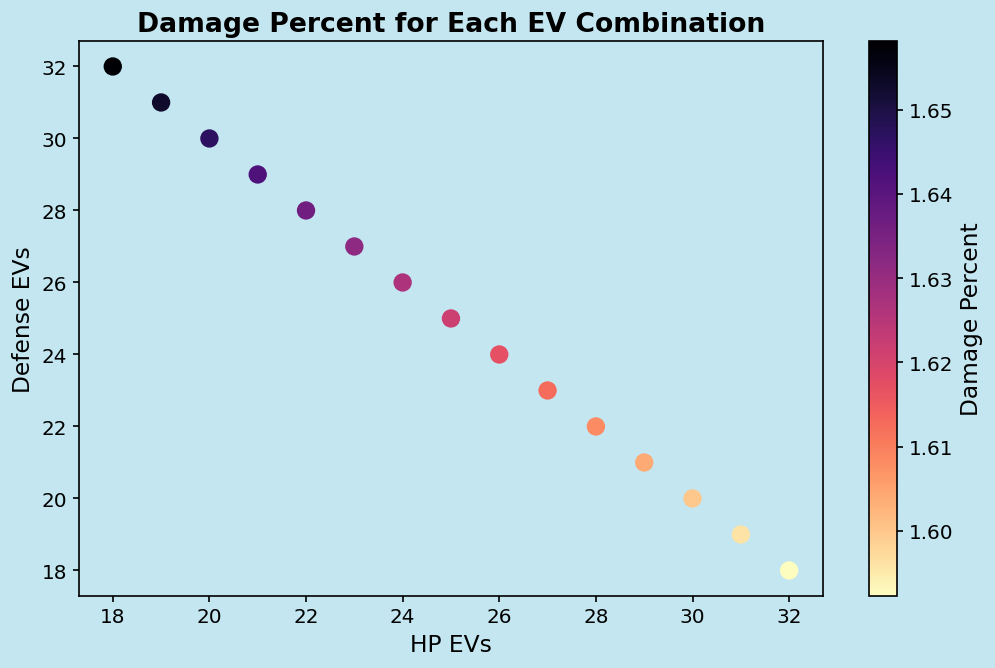

{'optimal_hp_evs': 32, 'optimal_defense_evs': 18, 'min_damage_percent': 1.5922852657546536}
Optimal HP EVs: 32
Optimal Defense EVs: 18
Minimum Damage Percent: 1.838977349181431


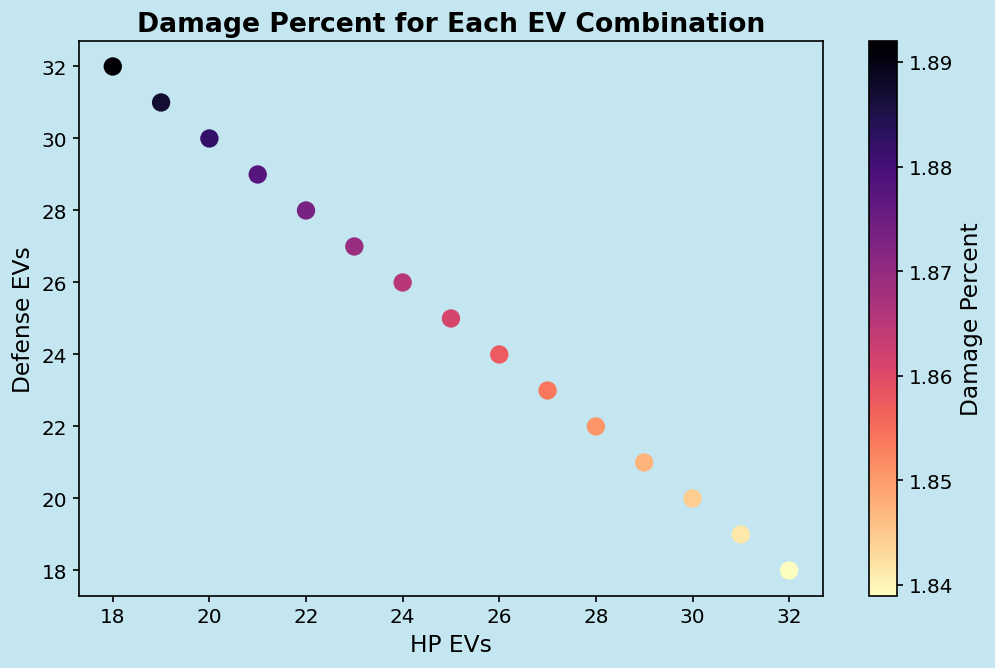

{'optimal_hp_evs': 32, 'optimal_defense_evs': 18, 'min_damage_percent': 1.838977349181431}
Optimal HP EVs: 32
Optimal Defense EVs: 18
Minimum Damage Percent: 2.085669432608208


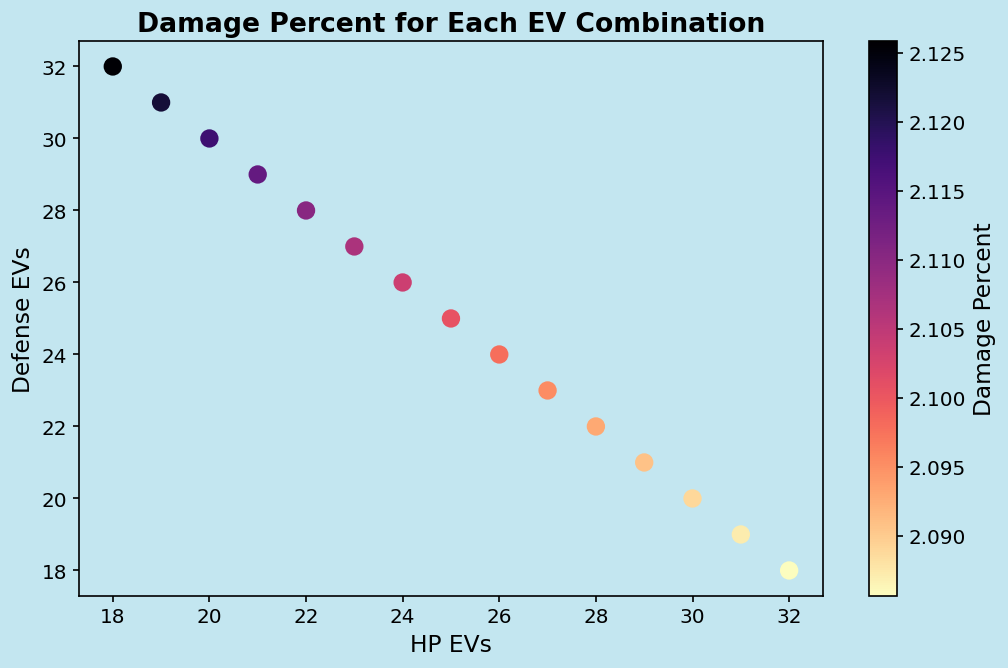

{'optimal_hp_evs': 32, 'optimal_defense_evs': 18, 'min_damage_percent': 2.085669432608208}
Optimal HP EVs: 32
Optimal Defense EVs: 18
Minimum Damage Percent: 2.332361516034985


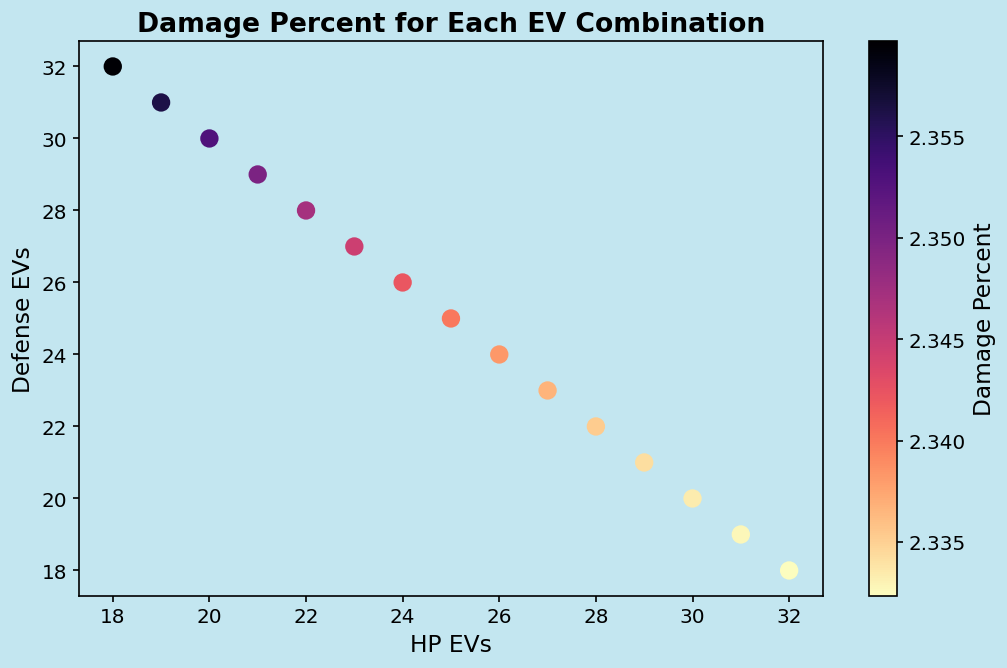

{'optimal_hp_evs': 32, 'optimal_defense_evs': 18, 'min_damage_percent': 2.332361516034985}
Optimal HP EVs: 29
Optimal Defense EVs: 21
Minimum Damage Percent: 2.577576193373527


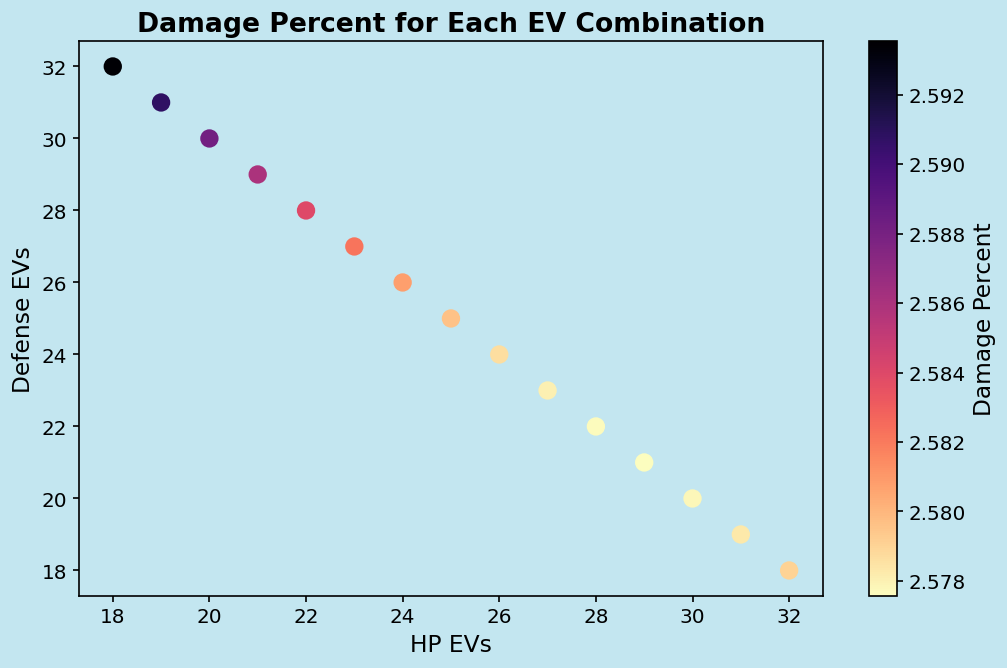

{'optimal_hp_evs': 29, 'optimal_defense_evs': 21, 'min_damage_percent': 2.577576193373527}
Optimal HP EVs: 25
Optimal Defense EVs: 25
Minimum Damage Percent: 2.8190476190476192


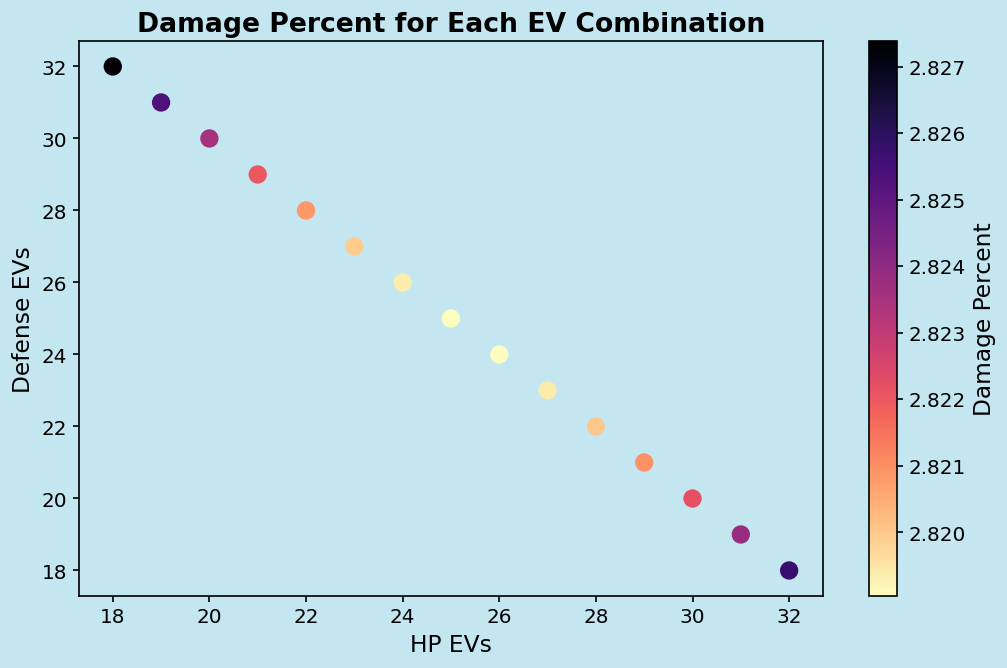

{'optimal_hp_evs': 25, 'optimal_defense_evs': 25, 'min_damage_percent': 2.8190476190476192}
Optimal HP EVs: 23
Optimal Defense EVs: 27
Minimum Damage Percent: 3.0576414024093785


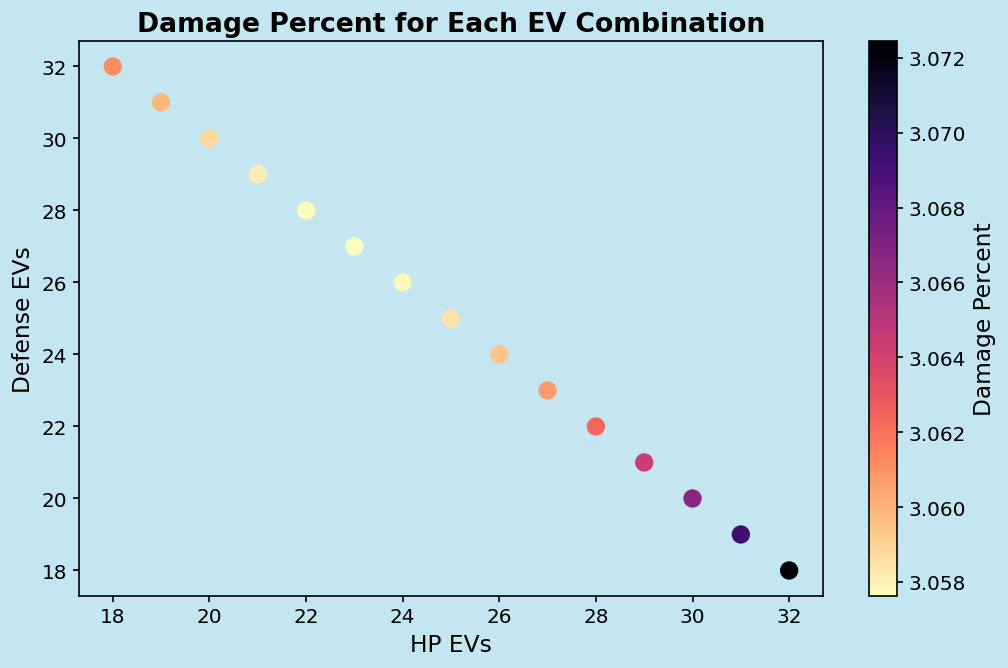

{'optimal_hp_evs': 23, 'optimal_defense_evs': 27, 'min_damage_percent': 3.0576414024093785}
Optimal HP EVs: 20
Optimal Defense EVs: 30
Minimum Damage Percent: 3.294117647058823


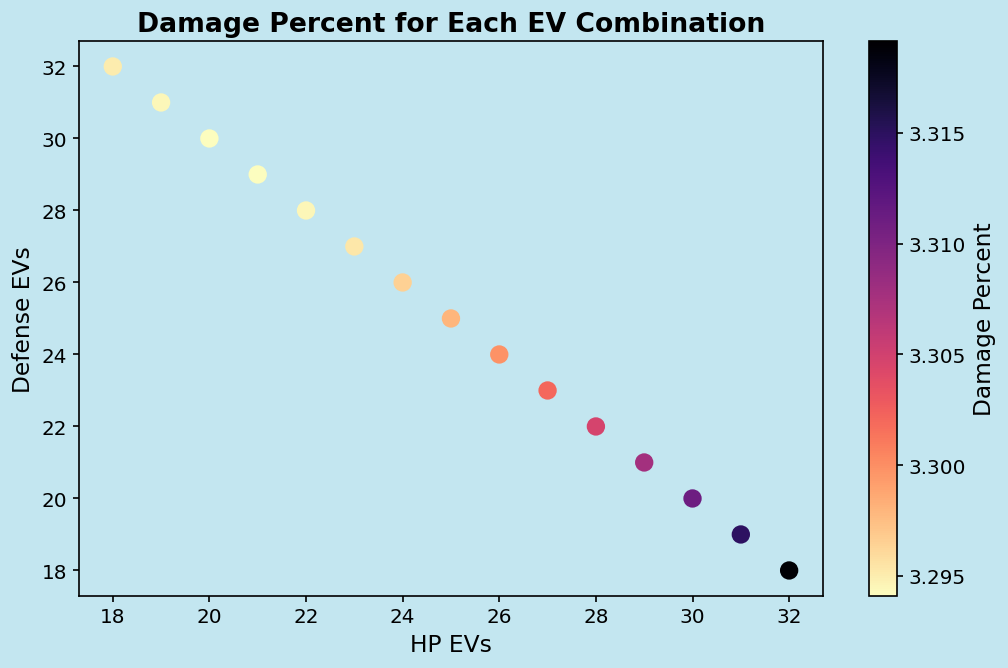

{'optimal_hp_evs': 20, 'optimal_defense_evs': 30, 'min_damage_percent': 3.294117647058823}


In [33]:
#def optimize_damage_percent(base_health, base_defense, total_evs, def_mult=1, atk=150, power=100, level=50):
for i in range(10):

    results = optimize_damage_percent(
        base_health=75,
        base_defense=60,
        total_evs=50,
        def_mult = 1,
        atk = 100,
        power = i
    )

    print(results)

In [34]:


# def parse_bonuses(text):
#     # "1.5,2,0.75" -> [1.5, 2.0, 0.75]
#     return [float(x.strip()) for x in text.split(",") if x.strip()]

# def run_optimizer(defense_info, attacks):
#     # TODO: call your existing damage_percent + optimized_evs pipeline here.
#     # Return a dict/list with results.

#     base_health = defense_info['base_health']
#     base_defense = defense_info['base_defense']
#     base_special_defense = defense_info['base_special_defense']
#     level = 50

#     attackN = 0
#     for a in attacks:
#         print(f"Optimizing for {a['name']}...")
#         for i, hp in enumerate(np.arange(0, 33)):
#             for j, defense in enumerate(np.arange(0, 33)):
#                 effective_defense = base_defense if a['PhySpec'] == "Physical" else base_special_defense
#                 evs_map[i, j] = damage_percent(defense_evs = defense, health_evs = hp, base_health = base_health, base_defense = effective_defense, total_evs = 64, def_mult = 1, atk = a['atk'], power = a['power'], level = level, bonus = a['bonus'])
#                 if evs_map[i, j] != 0 and evs_map[i, j] < 100:
#                     attacks[attackN]['evs'].append((hp, defense, evs_map[i, j]))
#                 else:
#                     attacks[attackN]['evs'].append((hp, defense, 0))
#         attackN += 1

#     return {"attacks": attacks}

# def best_optimized_evs(optimized_evs):
#     optimized_evs = {hp: {"defense": None, "special_defense": None} for hp in range(33)}

#     for a in attacks:
#         #for each hp ev value get the lowest defense evs and lowest special defense evs and attach to optimized_evs dict
#         for hp in range(33):
#             defense_evs = [ev[1] for ev in a['evs'] if ev[0] == hp and ev[2] != 0]
#             damage_percents = [ev[2] for ev in a['evs'] if ev[0] == hp and ev[2] != 0]

#             if len(defense_evs) > 0:
#                 min_defense_evs = min(defense_evs)
#                 if a['PhySpec'] == "Physical":
#                     optimized_evs[hp]['defense'] = min_defense_evs
#                     optimized_evs[hp]['defense_percent'] = damage_percents[defense_evs.index(min_defense_evs)]
#                 else:
#                     optimized_evs[hp]['special_defense'] = min_defense_evs
#                     optimized_evs[hp]['special_defense_percent'] = damage_percents[defense_evs.index(min_defense_evs)]
#             else:
#                 if a['PhySpec'] == "Physical":
#                     optimized_evs[hp]['defense'] = None
#                     optimized_evs[hp]['defense_percent'] = None
#                 else:
#                     optimized_evs[hp]['special_defense'] = None
#                     optimized_evs[hp]['special_defense_percent'] = None


#     for hp in range(33):
#         if optimized_evs[hp]['defense'] is None or optimized_evs[hp]['special_defense'] is None:
#             #remove key
#             del optimized_evs[hp]
#             continue
#         defense_evs = optimized_evs[hp]['defense'] if optimized_evs[hp]['defense'] is not None else 0
#         special_defense_evs = optimized_evs[hp]['special_defense'] if optimized_evs[hp]['special_defense'] is not None else 0
#         total_evs = hp + defense_evs + special_defense_evs
#         optimized_evs[hp]['total_evs'] = total_evs
#     return optimized_evs

# def on_add_attack():
#     try:
#         attack = {
#             "name": name_var.get().strip(),
#             "power": int(power_var.get()),
#             "atk": int(atk_var.get()),
#             "PhySpec": physpec_var.get(),
#             "bonus": parse_bonuses(bonus_var.get()),
#             "evs": []
#         }
#         if not attack["name"]:
#             raise ValueError("Attack name is required.")
#         attacks.append(attack)
#         attacks_list.insert(tk.END, f'{attack["name"]} | {attack["PhySpec"]} | Pwr {attack["power"]} | Atk {attack["atk"]} | bonus={attack["bonus"]}')
#         name_var.set("")
#         power_var.set("")
#         atk_var.set("")
#         bonus_var.set("1")
#     except Exception as e:
#         messagebox.showerror("Invalid Attack Input", str(e))

# def on_run():
#     try:
#         defense_info = {
#             "base_health": int(base_hp_var.get()),
#             "base_defense": int(base_def_var.get()),
#             "base_special_defense": int(base_spdef_var.get())
#         }
#         if not attacks:
#             raise ValueError("Add at least one attack first.")

#         result = run_optimizer(defense_info, attacks)
#         evs = best_optimized_evs(result)
#         result_box.delete("1.0", tk.END)
#         result_box.insert(
#             tk.END,
#             json.dumps(
#                 evs,
#                 indent=2,
#                 default=lambda o: int(o) if isinstance(o, np.integer)
#                 else float(o) if isinstance(o, np.floating)
#                 else o.tolist() if isinstance(o, np.ndarray)
#                 else str(o)
#             )
#         )
#     except Exception as e:
#         messagebox.showerror("Run Failed", str(e))

# # App state
# attacks = []

# # UI
# root = tk.Tk()
# root.title("Pokemon EV Optimizer")
# root.geometry("760x560")

# main = ttk.Frame(root, padding=12)
# main.pack(fill="both", expand=True)

# # Defense inputs
# ttk.Label(main, text="Defense Info", font=("Segoe UI", 11, "bold")).grid(row=0, column=0, sticky="w", pady=(0, 6))
# base_hp_var = tk.StringVar(value="88")
# base_def_var = tk.StringVar(value="80")
# base_spdef_var = tk.StringVar(value="95")

# ttk.Label(main, text="Base HP").grid(row=1, column=0, sticky="w")
# ttk.Entry(main, textvariable=base_hp_var, width=10).grid(row=1, column=1, sticky="w")

# ttk.Label(main, text="Base Def").grid(row=1, column=2, sticky="w")
# ttk.Entry(main, textvariable=base_def_var, width=10).grid(row=1, column=3, sticky="w")

# ttk.Label(main, text="Base SpDef").grid(row=1, column=4, sticky="w")
# ttk.Entry(main, textvariable=base_spdef_var, width=10).grid(row=1, column=5, sticky="w")

# # Attack inputs
# ttk.Separator(main, orient="horizontal").grid(row=2, column=0, columnspan=6, sticky="ew", pady=10)
# ttk.Label(main, text="Attack Input", font=("Segoe UI", 11, "bold")).grid(row=3, column=0, sticky="w", pady=(0, 6))

# name_var = tk.StringVar()
# power_var = tk.StringVar()
# atk_var = tk.StringVar()
# bonus_var = tk.StringVar(value="1.5,2")
# physpec_var = tk.StringVar(value="Physical")

# ttk.Label(main, text="Name").grid(row=4, column=0, sticky="w")
# ttk.Entry(main, textvariable=name_var, width=16).grid(row=4, column=1, sticky="w")

# ttk.Label(main, text="Power").grid(row=4, column=2, sticky="w")
# ttk.Entry(main, textvariable=power_var, width=10).grid(row=4, column=3, sticky="w")

# ttk.Label(main, text="Atk").grid(row=4, column=4, sticky="w")
# ttk.Entry(main, textvariable=atk_var, width=10).grid(row=4, column=5, sticky="w")

# ttk.Label(main, text="Type").grid(row=5, column=0, sticky="w")
# ttk.Combobox(main, textvariable=physpec_var, values=["Physical", "Special"], state="readonly", width=12).grid(row=5, column=1, sticky="w")

# ttk.Label(main, text="Bonuses (comma-separated)").grid(row=5, column=2, sticky="w")
# ttk.Entry(main, textvariable=bonus_var, width=24).grid(row=5, column=3, columnspan=3, sticky="w")

# ttk.Button(main, text="Add Attack", command=on_add_attack).grid(row=6, column=0, pady=8, sticky="w")

# attacks_list = tk.Listbox(main, height=8, width=95)
# attacks_list.grid(row=7, column=0, columnspan=6, sticky="ew")

# ttk.Button(main, text="Run Optimization", command=on_run).grid(row=8, column=0, pady=10, sticky="w")

# result_box = tk.Text(main, height=10, width=95)
# result_box.grid(row=9, column=0, columnspan=6, sticky="nsew")

# main.grid_rowconfigure(9, weight=1)
# main.grid_columnconfigure(5, weight=1)

# root.mainloop()